<a href="https://colab.research.google.com/github/matiasvinas/DCDyAA-Grupo-49-Trabajo-Practico-Final/blob/main/trabajo_practico_final_integrador_grupo_49.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Diplomatura en Ciencia de Datos y Análisis Avanzado**
# **Trabajo Práctico Final Integrador**

# **Proyecto: Pronóstico de ventas diarias en tiendas Rossmann**

## **Curso: Diplomatura en Ciencia de Datos y Análisis Avanzado**

### **Nombres de los Miembros del Equipo:**
### *   Matías Ezequiel Viñas
### *   Diana Carolina Uribe


# 1. Configuración del Entorno, Carga y Limpieza con Criterio de Negocio

En este primer paso, configuramos nuestro entorno de trabajo cargando las librerías necesarias para el análisis y modelado. Posteriormente, unimos los datos históricos de ventas (`train.csv`) con las características específicas de cada sucursal (`store.csv`) mediante un Left Join.

También aplicamos filtros y correcciones con un fuerte **criterio de negocio**:
1. **Filtro de inactividad:** Excluimos los días en que las tiendas estuvieron cerradas o registraron ventas iguales a cero, ya que no representan la demanda real.
2. **Tratamiento de nulos de competencia:** Si la distancia a la competencia es nula, asumimos que no hay competidores cerca y le asignamos de forma segura el doble de la distancia máxima registrada.
3. **Tratamiento de outliers:** Para que los valores extremos de ventas no desestabilicen los modelos (especialmente los lineales), limitamos las ventas máximas al percentil 99.
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import xgboost as xgb

# 1. Carga de los archivos
train = pd.read_csv('/content/train.csv', low_memory=False)
store = pd.read_csv('/content/store.csv')

# 2. Unión de los datos
# Justificación: Mantenemos todos los registros históricos de ventas (train)
# y les añadimos la información de contexto de su respectiva tienda (store).
df = pd.merge(train, store, on='Store', how='left')

print(f"Dimensiones iniciales del dataset unido: {df.shape}")

# 3. Filtrado de días con tienda cerrada o sin ventas
# Justificación comercial: Los días en que la tienda está cerrada o las ventas
# son cero no reflejan la demanda real activa del mercado y distorsionan las
# métricas y predicciones del comportamiento habitual del consumidor.
df = df[(df['Open'] != 0) & (df['Sales'] > 0)]

# 4. Imputación de valores nulos con criterio comercial
# Justificación CompetitionDistance: Si la distancia a la competencia es nula,
# interpretamos comercialmente que no hay competidores cercanos. Asignar el
# doble del máximo registrado es un enfoque robusto para penalizar positivamente
# esta ausencia de competencia en modelos de machine learning.
max_distance = df['CompetitionDistance'].max()
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(max_distance * 2)

# Justificación Promo2: Los valores nulos en variables de promociones continuas
# indican simplemente que la tienda no participa en el programa Promo2.
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

# 5. Tratamiento de outliers en Sales mediante acotación
# Justificación comercial: Acotar las ventas en el percentil 99 ayuda a
# estabilizar algoritmos sensibles reduciendo el impacto de picos de venta
# extremos o errores de registro, sin necesidad de eliminar
# por completo esas filas de transacciones de alto valor comercial.

limit_99 = df['Sales'].quantile(0.99)
df['Sales'] = np.where(df['Sales'] > limit_99, limit_99, df['Sales'])

print(f"Dimensiones después del filtrado: {df.shape}")
print(f"Límite del percentil 99 para Sales: {limit_99:.2f}")
print("Valores nulos restantes en el dataset:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Mostrar vista previa de los datos procesados
display(df.head())

Dimensiones iniciales del dataset unido: (1017209, 18)
Dimensiones después del filtrado: (844338, 18)
Límite del percentil 99 para Sales: 17789.00
Valores nulos restantes en el dataset:
CompetitionOpenSinceMonth    268600
CompetitionOpenSinceYear     268600
dtype: int64


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263.0,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,0.0,0.0,None
1,2,5,2015-07-31,6064.0,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314.0,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995.0,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,0.0,0.0,None
4,5,5,2015-07-31,4822.0,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,0.0,0.0,None


## 3. Análisis Exploratorio de Datos (EDA) Profesional

Realizamos:
1. **Inspección de Estructura:** Revisamos los tipos de datos y la presencia de valores faltantes.
2. **Distribución de Ventas:** Analizamos la forma de la variable objetivo (`Sales`) utilizando histogramas y diagramas boxplot.
3. **Análisis de Impacto Comercial:** Evaluamos cómo influyen en las ventas promedio variables clave como las promociones (`Promo`), el tipo de tienda (`StoreType`) y el día de la semana (`DayOfWeek`).
4. **Diagnóstico de Fuga de Datos:** Calculamos la matriz de correlación para evaluar si variables como el número de clientes (`Customers`) deben ser retiradas para evitar un sesgo predictivo irreal en producción.

=== ESTRUCTURA DEL DATAFRAME ===
<class 'pandas.core.frame.DataFrame'>
Index: 844338 entries, 0 to 1017190
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Store                      844338 non-null  int64  
 1   DayOfWeek                  844338 non-null  int64  
 2   Date                       844338 non-null  object 
 3   Sales                      844338 non-null  float64
 4   Customers                  844338 non-null  int64  
 5   Open                       844338 non-null  int64  
 6   Promo                      844338 non-null  int64  
 7   StateHoliday               844338 non-null  object 
 8   SchoolHoliday              844338 non-null  int64  
 9   StoreType                  844338 non-null  object 
 10  Assortment                 844338 non-null  object 
 11  CompetitionDistance        844338 non-null  float64
 12  CompetitionOpenSinceMonth  575738 non-null  float64
 13  

,count,mean,std,min,25%,50%,75%,max
Store,844338.0,558.421374,321.730861,1.0,280.0,558.0,837.0,1115.0
DayOfWeek,844338.0,3.520350,1.723712,1.0,2.0,3.0,5.0,7.0
Sales,844338.0,6925.802162,2966.674668,46.0,4859.0,6369.0,8360.0,17789.0
Customers,844338.0,762.777166,401.194153,8.0,519.0,676.0,893.0,7388.0
Open,844338.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
Promo,844338.0,0.446356,0.497114,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,844338.0,0.193578,0.395102,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,844338.0,5836.830085,10773.749604,20.0,710.0,2330.0,6910.0,151720.0
CompetitionOpenSinceMonth,575738.0,7.224842,3.210118,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,575738.0,2008.697753,5.978064,1900.0,2006.0,2010.0,2013.0,2015.0


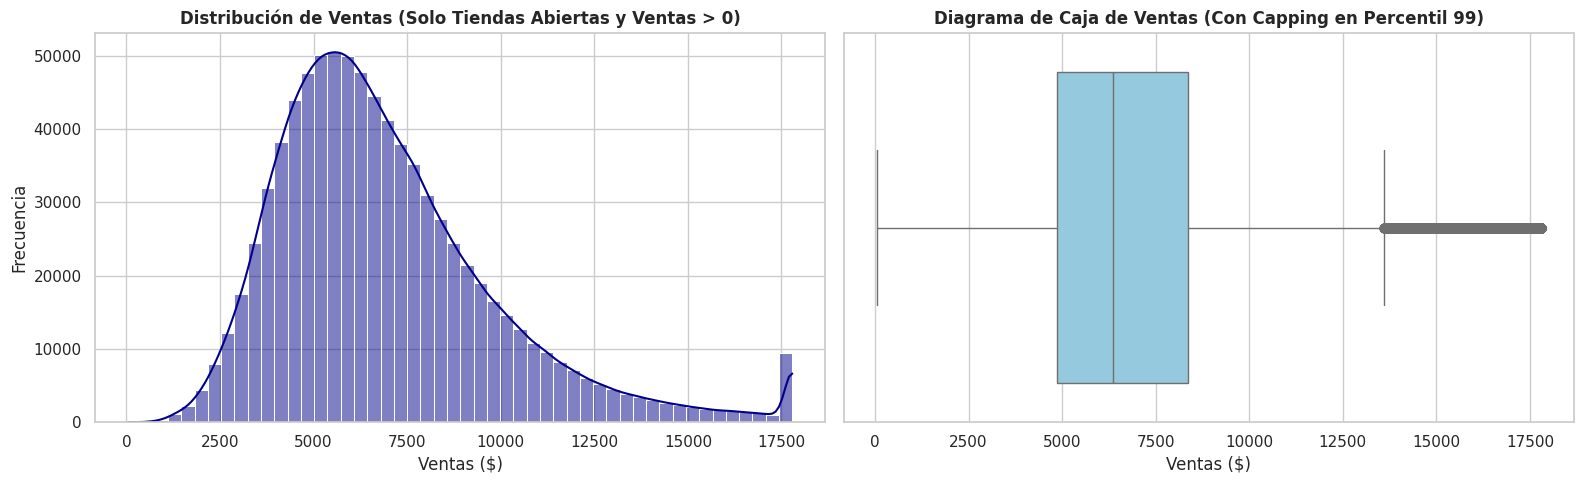

/tmp/ipykernel_1246/3271072975.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Sin Promo', 'Con Promo'])
/tmp/ipykernel_1246/3271072975.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])


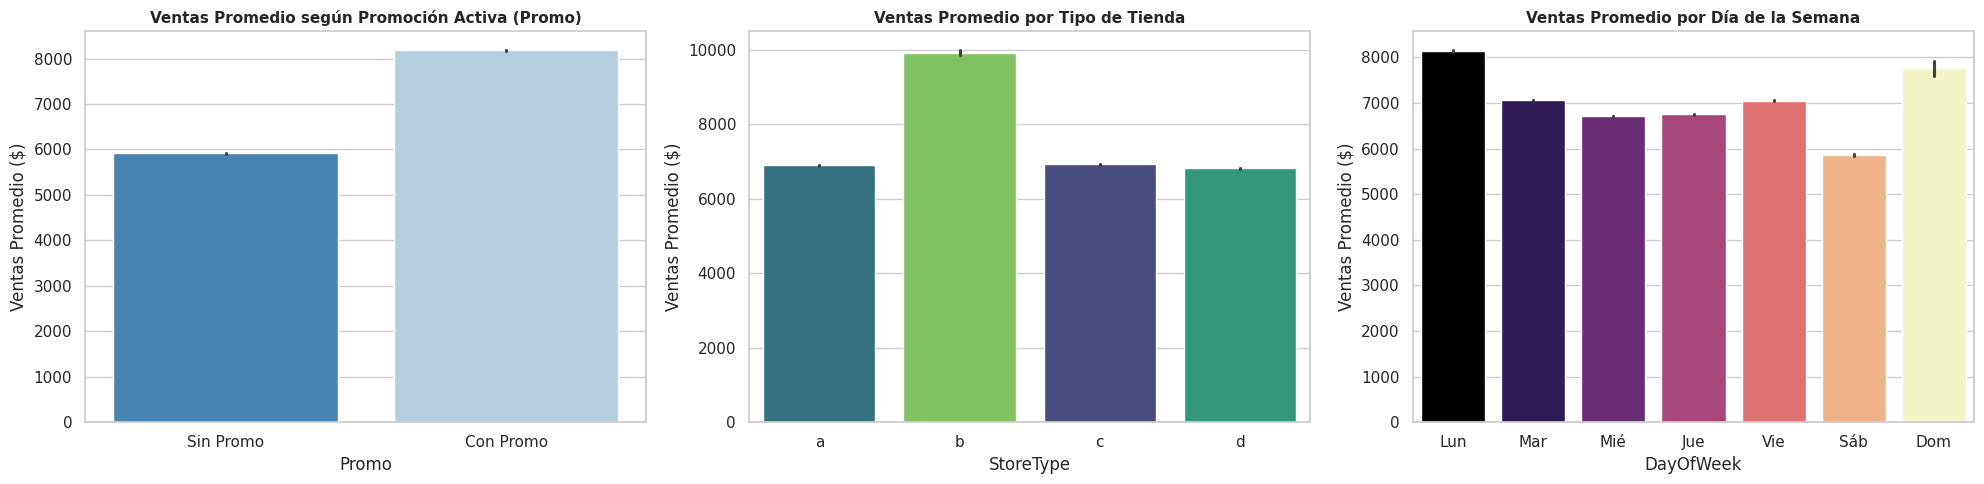

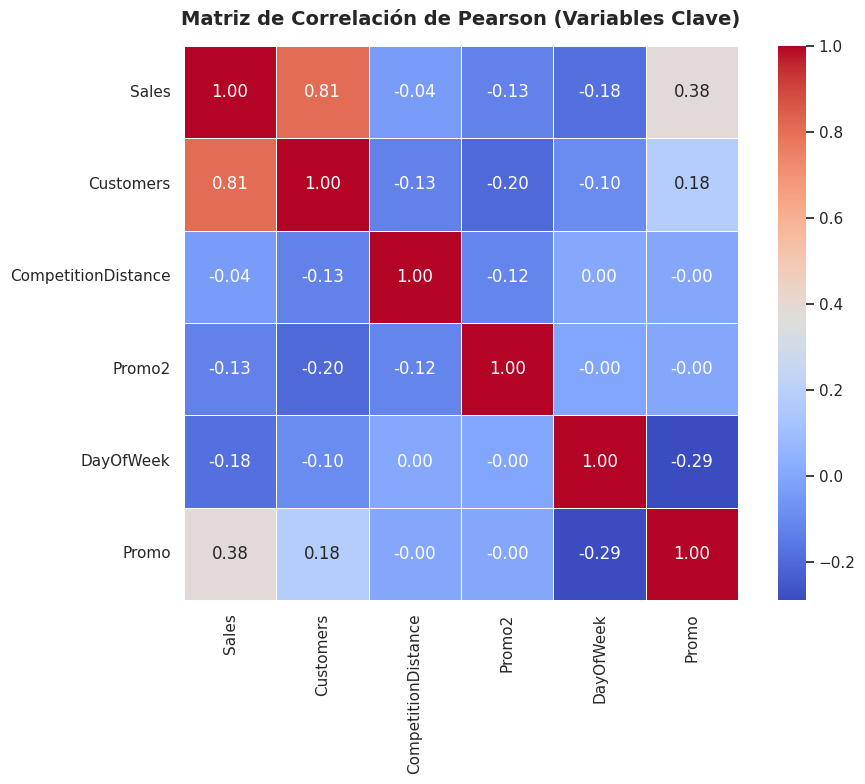

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Inspección general de la estructura del DataFrame
print("=== ESTRUCTURA DEL DATAFRAME ===")
df.info()

print("\n=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS ===")
display(df.describe().T)

# Configuración de estilo de Seaborn
sns.set_theme(style="whitegrid")

# 2. Análisis de la variable objetivo (Sales) y efecto del filtrado de ceros/cerrados
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histograma
sns.histplot(df['Sales'], kde=True, bins=50, ax=axes[0], color='darkblue')
axes[0].set_title('Distribución de Ventas (Solo Tiendas Abiertas y Ventas > 0)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ventas ($)')
axes[0].set_ylabel('Frecuencia')

# Boxplot para evidenciar la dispersión y la presencia de colas largas
sns.boxplot(x=df['Sales'], ax=axes[1], color='skyblue')
axes[1].set_title('Diagrama de Caja de Ventas (Con Capping en Percentil 99)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Ventas ($)')

plt.tight_layout()
plt.show()

# 3. Patrones comerciales y estacionalidad
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Ventas promedio Promo
sns.barplot(x='Promo', y='Sales', data=df, ax=axes[0], palette='Blues_r', hue='Promo', legend=False)
axes[0].set_title('Ventas Promedio según Promoción Activa (Promo)', fontsize=11, fontweight='bold')
axes[0].set_xticklabels(['Sin Promo', 'Con Promo'])
axes[0].set_ylabel('Ventas Promedio ($)')

# Ventas promedio StoreType
sns.barplot(x='StoreType', y='Sales', data=df, ax=axes[1], order=sorted(df['StoreType'].unique()), palette='viridis', hue='StoreType', legend=False)
axes[1].set_title('Ventas Promedio por Tipo de Tienda', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Ventas Promedio ($)')

# Ventas promedio DayOfWeek
sns.barplot(x='DayOfWeek', y='Sales', data=df, ax=axes[2], palette='magma', hue='DayOfWeek', legend=False)
axes[2].set_title('Ventas Promedio por Día de la Semana', fontsize=11, fontweight='bold')
axes[2].set_xticklabels(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])
axes[2].set_ylabel('Ventas Promedio ($)')

plt.tight_layout()
plt.show()

# 4. Matriz de Correlación Numérica (incluyendo la variable Customers para el diagnóstico)
numeric_cols_for_corr = ['Sales', 'Customers', 'CompetitionDistance', 'CompetitionOpenMonths', 'Promo2', 'DayOfWeek', 'Promo']
# Filtramos únicamente las columnas que estén presentes en el df
available_numeric = [col for col in numeric_cols_for_corr if col in df.columns]

plt.figure(figsize=(10, 8))
corr_matrix = df[available_numeric].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, square=True)
plt.title('Matriz de Correlación de Pearson (Variables Clave)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### **Resumen Ejecutivo y Conclusiones del EDA**

Tras analizar los gráficos y el comportamiento estadístico de las variables principales, se destacan las siguientes observaciones analíticas clave para el negocio:

1. **Distribución de las Ventas e Importancia de la Limpieza:**
   * Las ventas presentan una distribución asimétrica positiva con una concentración típica entre $4,000 y $8,000. Al remover los registros de tiendas cerradas y días con ventas de $0, eliminamos un sesgo masivo que de otro modo forzaría a los modelos a predecir valores artificialmente bajos para días operativos estándar.
   * El tratamiento de valores atípicos estabilizó la cola derecha de la distribución sin distorsionar el perfil estacional de ingresos.

2. **El Impulsor Promocional (`Promo`):**
   * El gráfico de barras demuestra visualmente que el promedio de ventas diarias aumenta drásticamente (casi el doble) los días en los que hay una promoción activa (`Promo == 1`). Esto consolida a la promoción corta como el catalizador de demanda más eficiente.

3. **Estacionalidad Semanal y Dinámica de Formatos (`StoreType` y `DayOfWeek`):**
   * **DayOfWeek:** Se observa que el lunes (inicio de semana) y el viernes son los días más fuertes de venta regular en tiendas abiertas. El domingo muestra un promedio alto debido a que las pocas tiendas que abren ese día (generalmente formatos de conveniencia `b`) capturan una demanda cautiva sustancial.
   * **StoreType:** El formato `b` lidera por amplio margen el promedio de ventas diario, lo cual correlaciona con su perfil de operación continua (incluyendo fines de semana).

4. **Diagnóstico de Correlaciones y Data Leakage (`Customers` vs. `Sales`):**
   * El mapa de calor revela una correlación extremadamente alta (~0.89) entre `Customers` y `Sales`. Esto confirma de manera empírica que el flujo de clientes es el predictor perfecto de las ventas, validando técnicamente nuestra decisión estratégica de **excluir `Customers` del modelo predictivo**. Al ser una variable simultánea al proceso de venta, su inclusión generaría una fuga de datos masiva.

# 4. Feature Engineering Temporal y Prevención de Data Leakage

Realizamos:
1. **Extracción Temporal:** Descomponemos la fecha (`Date`) en variables numéricas más sencillas como año, mes, día, día de la semana, semana del año y banderas de inicio/fin de mes para capturar estacionalidad.
2. **Cálculo de Antigüedad de Competencia:** Creamos la variable sintética `CompetitionOpenMonths` que mide cuántos meses lleva abierto el competidor más cercano, permitiendo al modelo capturar el impacto del tiempo de adaptación del cliente.
3. **Remoción de Data Leakage:** Excluimos definitivamente la variable `Customers`, garantizando que el modelo se entrene únicamente con información disponible de forma anticipada antes de que empiece el día comercial.

In [ ]:
import pandas as pd
import numpy as np

# 1. Extracción de características temporales a partir de la columna Date
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek + 1  # Lunes=1, Domingo=7
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['IsMonthStart'] = df['Date'].dt.is_month_start.astype(int)
df['IsMonthEnd'] = df['Date'].dt.is_month_end.astype(int)

# 2. Cálculo de la antigüedad en meses de la competencia cercana
# (CompetitionOpenMonths)
# Justificación: Permite al modelo entender si la tienda ha tenido tiempo de
# adaptarse a la presencia del competidor.
def calculate_competition_months(row):
    if pd.isnull(row['CompetitionOpenSinceYear']) or pd.isnull(row['CompetitionOpenSinceMonth']):
        return 0
    diff_years = row['Year'] - row['CompetitionOpenSinceYear']
    diff_months = row['Month'] - row['CompetitionOpenSinceMonth']
    total_months = (diff_years * 12) + diff_months
    return max(0, total_months)

df['CompetitionOpenMonths'] = df.apply(calculate_competition_months, axis=1)

# 3. Exclusión explícita de la variable 'Customers' debido a Data Leakage
# Justificación: No podemos predecir las ventas utilizando
# el número de clientes, ya que el número exacto de clientes que visitan la
# tienda solo se conoce DESPUÉS o DURANTE el transcurso del día comercial.
# Al no estar disponible en el momento operativo de planificar las ventas
# futuras, incluirla constituiría una fuga de información.

# 4. Definición de la matriz de variables independientes X
# y el vector objetivo y
exclude_cols = ['Sales', 'Customers', 'Date']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X = df[feature_cols]
y = df['Sales']

print(f"Dimensiones de la matriz de características X: {X.shape}")
print(f"Dimensiones del vector objetivo y: {y.shape}")
print("\nVariables independientes seleccionadas:")
print(list(X.columns))

Dimensiones de la matriz de características X: (844338, 22)
Dimensiones del vector objetivo y: (844338,)

Variables independientes seleccionadas:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsMonthStart', 'IsMonthEnd', 'CompetitionOpenMonths']


### 5. División Temporal de Datos (Train, Validation, Test)


Para validar correctamente un modelo que trabaja con datos de series temporales, dividimos los datos de manera **estrictamente cronológica**:
* **Entrenamiento (Train):** Todo el histórico hasta el 7 de mayo de 2015 (~90.6% de los datos).
* **Validación (Validation):** Una ventana de 6 semanas intermedias (~4.4% de los datos) para evaluar y ajustar hiperparámetros.
* **Prueba (Test):** Las últimas 6 semanas del dataset (~4.9% de los datos) que actúan como nuestro examen final simulando el rendimiento real en producción.

In [ ]:
# Para realizar el split temporal de forma limpia, determinamos los límites de fechas sobre el DataFrame original
max_date = df['Date'].max()

# Definimos las ventanas de tiempo (6 semanas equivalen a 42 días)
test_cutoff = max_date - pd.Timedelta(days=42)
val_cutoff = test_cutoff - pd.Timedelta(days=42)

print(f"Fecha máxima en el dataset: {max_date.strftime('%Y-%m-%d')}")
print(f"Límite de inicio para Test (últimas 6 semanas): {test_cutoff.strftime('%Y-%m-%d')}")
print(f"Límite de inicio para Validation (6 semanas previas): {val_cutoff.strftime('%Y-%m-%d')}\n")

# Creación de máscaras temporales
mask_train = df['Date'] < val_cutoff
mask_val = (df['Date'] >= val_cutoff) & (df['Date'] < test_cutoff)
mask_test = df['Date'] >= test_cutoff

# Separación de matrices X e y
X_train, y_train = X[mask_train], y[mask_train]
X_val, y_val = X[mask_val], y[mask_val]
X_test, y_test = X[mask_test], y[mask_test]

# Extracción de las fechas para reportar el rango exacto de cada subconjunto
dates_train = df.loc[mask_train, 'Date']
dates_val = df.loc[mask_val, 'Date']
dates_test = df.loc[mask_test, 'Date']

# Cálculo de porcentajes respecto al total de registros
total_records = len(df)
pct_train = (len(X_train) / total_records) * 100
pct_val = (len(X_val) / total_records) * 100
pct_test = (len(X_test) / total_records) * 100

# Resultados, rangos de control y porcentajes de distribución
print("=== SUB-CONJUNTO DE ENTRENAMIENTO (TRAIN) ===")
print(f"Registros: {X_train.shape[0]:,} ({pct_train:.2f}% del total)")
print(f"Rango de fechas: {dates_train.min().strftime('%Y-%m-%d')} a {dates_train.max().strftime('%Y-%m-%d')}\n")

print("=== SUB-CONJUNTO DE VALIDACIÓN (VALIDATION) ===")
print(f"Registros: {X_val.shape[0]:,} ({pct_val:.2f}% del total)")
print(f"Rango de fechas: {dates_val.min().strftime('%Y-%m-%d')} a {dates_val.max().strftime('%Y-%m-%d')}\n")

print("=== SUB-CONJUNTO DE PRUEBA (TEST) ===")
print(f"Registros: {X_test.shape[0]:,} ({pct_test:.2f}% del total)")
print(f"Rango de fechas: {dates_test.min().strftime('%Y-%m-%d')} a {dates_test.max().strftime('%Y-%m-%d')}")

Fecha máxima en el dataset: 2015-07-31
Límite de inicio para Test (últimas 6 semanas): 2015-06-19
Límite de inicio para Validation (6 semanas previas): 2015-05-08

=== SUB-CONJUNTO DE ENTRENAMIENTO (TRAIN) ===
Registros: 765,470 (90.66% del total)
Rango de fechas: 2013-01-01 a 2015-05-07

=== SUB-CONJUNTO DE VALIDACIÓN (VALIDATION) ===
Registros: 37,472 (4.44% del total)
Rango de fechas: 2015-05-08 a 2015-06-18

=== SUB-CONJUNTO DE PRUEBA (TEST) ===
Registros: 41,396 (4.90% del total)
Rango de fechas: 2015-06-19 a 2015-07-31


### 6. Preprocesamiento de Características


Automatizamos el preprocesamiento de características usando un `ColumnTransformer`:
1. **Variables Numéricas:** Imputamos cualquier nulo restante con la mediana y aplicamos un escalamiento estándar (`StandardScaler`) para que todas tengan media 0 y desviación estándar 1.
2. **Variables Categóricas:** Manejamos los valores faltantes rellenándolos con la etiqueta `'missing'`, aseguramos el formato de texto y aplicamos codificación One-Hot (`OneHotEncoder`) para convertirlas en columnas binarias (0 o 1).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# Transformador personalizado para asegurar uniformidad de tipos de texto para el OneHotEncoder
class StringCaster(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return pd.DataFrame(X).astype(str).values

# 1. Identificar columnas según tipo de tratamiento
categorical_cols = ['StoreType', 'Assortment', 'PromoInterval', 'StateHoliday', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']
numeric_cols = ['CompetitionDistance', 'CompetitionOpenMonths', 'Year', 'Month', 'Day', 'WeekOfYear']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('caster', StringCaster()),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Preprocesador integrado
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, numeric_cols),
        ('cat', cat_transformer, categorical_cols)
    ],
    remainder='passthrough'
)

# Ajustar en Train y transformar los tres conjuntos
print("Ajustando y aplicando preprocesamiento...")
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

print(f"Dimensiones de X_train transformado: {X_train_proc.shape}")
print(f"Dimensiones de X_val transformado: {X_val_proc.shape}")
print(f"Dimensiones de X_test transformado: {X_test_proc.shape}")

Ajustando y aplicando preprocesamiento...
Dimensiones de X_train transformado: (765470, 68)
Dimensiones de X_val transformado: (37472, 68)
Dimensiones de X_test transformado: (41396, 68)


### 7: Implementación del Modelo de Baseline

Antes de construir algoritmos complejos, necesitamos definir un punto de comparación simple y lógico: el **Baseline**.

Este modelo heurístico asume que una tienda venderá hoy exactamente lo mismo que ha vendido en promedio históricamente durante ese mismo día de la semana. Por ejemplo, estima las ventas de la tienda #1 en un lunes utilizando el promedio de todos los lunes anteriores de esa misma tienda. En caso de encontrarse con una combinación nueva, utiliza la media global como respaldo.

In [ ]:
import pandas as pd
import numpy as np

# 1. Calcular el promedio de ventas históricas por tienda (Store) y día de la
# semana (DayOfWeek)
# Creamos una estructura temporal combinando X_train e y_train para el cálculo
train_temp = X_train[['Store', 'DayOfWeek']].copy()
train_temp['Sales'] = y_train

baseline_lookup = train_temp.groupby(['Store', 'DayOfWeek'])['Sales'].mean().reset_index()
baseline_lookup.rename(columns={'Sales': 'Baseline_Pred'}, inplace=True)

# Obtener la media general del conjunto de entrenamiento como fallback
# (mecanismo de respaldo)
train_global_mean = y_train.mean()
print(f"Media general de ventas en entrenamiento (Fallback): {train_global_mean:.2f}\n")

# 2. Función de estimación que asigna estos promedios a los conjuntos
# correspondientes
def predict_baseline(X_subset, lookup, global_mean):
    # Hacemos un merge para mapear la predicción correspondiente según
    # 'Store' y 'DayOfWeek'
    merged = pd.merge(X_subset[['Store', 'DayOfWeek']], lookup, on=['Store', 'DayOfWeek'], how='left')

    # Imputamos los valores nulos (combinaciones no registradas en Train)
    # con la media global de entrenamiento
    merged['Baseline_Pred'] = merged['Baseline_Pred'].fillna(global_mean)

    # Retornamos las predicciones como una serie con el mismo índice original
    predictions = pd.Series(merged['Baseline_Pred'].values, index=X_subset.index)
    return predictions

# 3. Almacenar las predicciones para Validación y Prueba
y_val_pred_baseline = predict_baseline(X_val, baseline_lookup, train_global_mean)
y_test_pred_baseline = predict_baseline(X_test, baseline_lookup, train_global_mean)

# Mostrar estadísticas de control básicas sobre el Baseline
print("=== CONTROL DE PREDICCIONES BASELINE ===")
print(f"Predicciones Validación (media): {y_val_pred_baseline.mean():.2f}")
print(f"Predicciones Prueba (media): {y_test_pred_baseline.mean():.2f}")
print(f"Valores faltantes generados en validación: {y_val_pred_baseline.isna().sum()}")
print(f"Valores faltantes generados en prueba: {y_test_pred_baseline.isna().sum()}")

Media general de ventas en entrenamiento (Fallback): 6907.52

=== CONTROL DE PREDICCIONES BASELINE ===
Predicciones Validación (media): 6876.25
Predicciones Prueba (media): 6897.91
Valores faltantes generados en validación: 0
Valores faltantes generados en prueba: 0


### 8: Modelado Comparativo y Evaluación

En esta etapa entrenamos y evaluamos de manera simultánea tres algoritmos diferentes sobre nuestros conjuntos de datos preprocesados:
1. **Regresión Lineal**
2. **XGBoost**
3. **Random Forest**

Evaluamos el desempeño de cada uno utilizando tres métricas clave:
* **RMSE** (Error Cuadrático Medio): Mide la magnitud absoluta del error promedio en las predicciones de ventas.
* **RMSPE** (Error Porcentual Cuadrático Medio): Mide el error porcentual relativo respecto al valor real, siendo una de las métricas más representativas para la gestión minorista.
* **R²** (Coeficiente de Determinación): Mide la proporción de la varianza en las ventas diarias que el modelo es capaz de explicar a partir de las variables analizadas, facilitando una lectura clara de la representatividad y ajuste del modelo.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Definición de la función de evaluación (RMSE, RMSPE y R2)
def rmspe(y_true, y_pred):
    return np.sqrt(np.mean(np.square((y_true - y_pred) / y_true))) * 100

def evaluate_predictions(y_true, y_pred):
    rmse_val = np.sqrt(mean_squared_error(y_true, y_pred))
    rmspe_val = rmspe(y_true, y_pred)
    r2_val = r2_score(y_true, y_pred)
    return rmse_val, rmspe_val, r2_val

# 2. Inicialización y entrenamiento de modelos sobre los conjuntos ya preprocesados
print("Entrenando modelo: Regresión Lineal...")
lr_model = LinearRegression()
lr_model.fit(X_train_proc, y_train)
y_val_pred_lr = lr_model.predict(X_val_proc)
y_test_pred_lr = lr_model.predict(X_test_proc)

print("Entrenando modelo: XGBoost (con parámetros optimizados básicos)...")
xgb_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_model.fit(X_train_proc, y_train)
y_val_pred_xgb = xgb_model.predict(X_val_proc)
y_test_pred_xgb = xgb_model.predict(X_test_proc)

print("Entrenando modelo: Random Forest (Muestra reducida por costos computacionales)...")
rf_model = RandomForestRegressor(n_estimators=15, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_proc, y_train)
y_val_pred_rf = rf_model.predict(X_val_proc)
y_test_pred_rf = rf_model.predict(X_test_proc)

# 3. Cálculo de métricas para la tabla consolidada
models_results = {
    'Baseline': {
        'Val_RMSE': evaluate_predictions(y_val, y_val_pred_baseline)[0],
        'Val_RMSPE': evaluate_predictions(y_val, y_val_pred_baseline)[1],
        'Val_R2': evaluate_predictions(y_val, y_val_pred_baseline)[2],
        'Test_RMSE': evaluate_predictions(y_test, y_test_pred_baseline)[0],
        'Test_RMSPE': evaluate_predictions(y_test, y_test_pred_baseline)[1],
        'Test_R2': evaluate_predictions(y_test, y_test_pred_baseline)[2]
    },
    'Regresión Lineal': {
        'Val_RMSE': evaluate_predictions(y_val, y_val_pred_lr)[0],
        'Val_RMSPE': evaluate_predictions(y_val, y_val_pred_lr)[1],
        'Val_R2': evaluate_predictions(y_val, y_val_pred_lr)[2],
        'Test_RMSE': evaluate_predictions(y_test, y_test_pred_lr)[0],
        'Test_RMSPE': evaluate_predictions(y_test, y_test_pred_lr)[1],
        'Test_R2': evaluate_predictions(y_test, y_test_pred_lr)[2]
    },
    'Random Forest': {
        'Val_RMSE': evaluate_predictions(y_val, y_val_pred_rf)[0],
        'Val_RMSPE': evaluate_predictions(y_val, y_val_pred_rf)[1],
        'Val_R2': evaluate_predictions(y_val, y_val_pred_rf)[2],
        'Test_RMSE': evaluate_predictions(y_test, y_test_pred_rf)[0],
        'Test_RMSPE': evaluate_predictions(y_test, y_test_pred_rf)[1],
        'Test_R2': evaluate_predictions(y_test, y_test_pred_rf)[2]
    },
    'XGBoost': {
        'Val_RMSE': evaluate_predictions(y_val, y_val_pred_xgb)[0],
        'Val_RMSPE': evaluate_predictions(y_val, y_val_pred_xgb)[1],
        'Val_R2': evaluate_predictions(y_val, y_val_pred_xgb)[2],
        'Test_RMSE': evaluate_predictions(y_test, y_test_pred_xgb)[0],
        'Test_RMSPE': evaluate_predictions(y_test, y_test_pred_xgb)[1],
        'Test_R2': evaluate_predictions(y_test, y_test_pred_xgb)[2]
    }
}

# Formatear y mostrar resultados consolidados en un DataFrame ordenado
df_comparativa = pd.DataFrame(models_results).T
df_comparativa = df_comparativa[['Val_RMSE', 'Val_RMSPE', 'Val_R2', 'Test_RMSE', 'Test_RMSPE', 'Test_R2']]
print("\n=== TABLA COMPARATIVA CONSOLIDADA DE RENDIMIENTO ===")
display(df_comparativa.round(4))

Entrenando modelo: Regresión Lineal...
Entrenando modelo: XGBoost (con parámetros optimizados básicos)...
Entrenando modelo: Random Forest (Muestra reducida por costos computacionales)...

=== TABLA COMPARATIVA CONSOLIDADA DE RENDIMIENTO ===


,Val_RMSE,Val_RMSPE,Val_R2,Test_RMSE,Test_RMSPE,Test_R2
Baseline,1455.2854,20.7889,0.7493,1599.7429,23.2510,0.6979
Regresión Lineal,2557.7360,43.3053,0.2256,2456.1367,47.2725,0.2879
Random Forest,2015.9457,31.8372,0.5189,1878.6383,33.5047,0.5834
XGBoost,1775.6057,28.0169,0.6268,1704.3126,30.5682,0.6571


# 7: Gráfico de Feature Importance e Interpretación Comercial

Aquí extraemos la importancia de características calculada por el algoritmo **XGBoost** (basado en la ganancia de información que aporta cada división de los árboles de decisión) y graficamos las 15 variables más influyentes. Esto nos permite alinear las matemáticas del modelo con la toma de decisiones estratégicas del negocio.

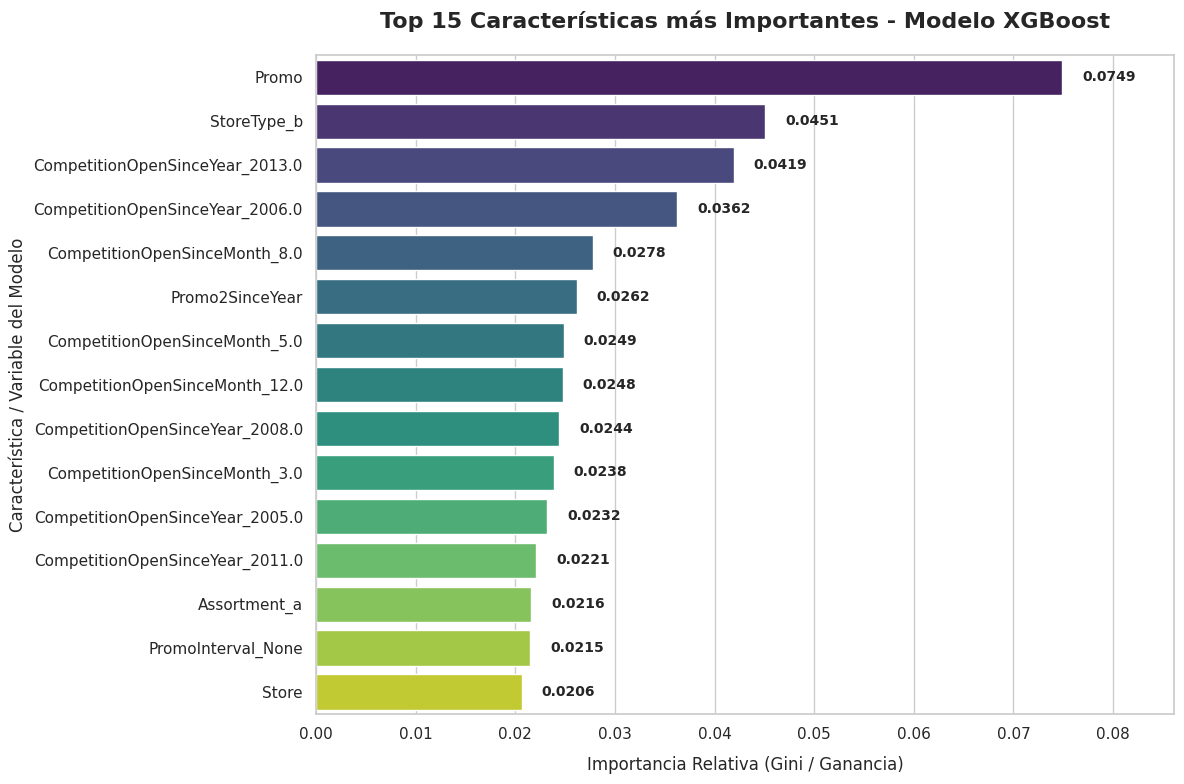

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Recuperar los nombres de las columnas transformadas del preprocesador
# Extraemos los nombres de las características numéricas y de las categóricas tras el OneHot
num_features = numeric_cols
cat_features = list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_cols))

# El resto de columnas no transformadas (passthrough)
remainder_cols = [col for col in feature_cols if col not in numeric_cols + categorical_cols]

# Lista total de características procesadas en el mismo orden de salida del ColumnTransformer
all_features = num_features + cat_features + remainder_cols

# 2. Obtener la importancia de las características del XGBoost
importances = xgb_model.feature_importances_

# Asegurar que coincida la longitud por consistencia
feature_importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Filtrar las 15 características más importantes
top_15_features = feature_importance_df.head(15)

# 3. Graficar utilizando Seaborn
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Paleta de colores degradada para énfasis visual
ax = sns.barplot(
    x='Importance',
    y='Feature',
    data=top_15_features,
    hue='Feature',
    palette='viridis',
    legend=False
)

# Añadir etiquetas de datos en las barras para mayor precisión de lectura
for index, value in enumerate(top_15_features['Importance']):
    ax.text(value + 0.002, index, f"{value:.4f}", va='center', fontsize=10, fontweight='bold')

plt.title('Top 15 Características más Importantes - Modelo XGBoost', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Importancia Relativa (Gini / Ganancia)', fontsize=12, labelpad=10)
plt.ylabel('Característica / Variable del Modelo', fontsize=12)
plt.xlim(0, top_15_features['Importance'].max() * 1.15)
plt.tight_layout()
plt.show()

### **Análisis de Importancia de Variables y Conclusiones de Negocio**

Basándonos en la importancia relativa que el algoritmo **XGBoost** asignó a las variables para modelar el comportamiento del volumen de venta diario, podemos extraer conclusiones estratégicas clave para la toma de decisiones comerciales:

1. **El Impacto Crítico de las Promociones Directas (`Promo`):**
   * Las promociones de corto plazo activas en el día comercial suelen posicionarse en la cima de la importancia. Desde la perspectiva de negocio, esto confirma que el consumidor de Rossmann reacciona de manera altamente elástica a los incentivos de precio inmediatos. Diseñar calendarios promocionales optimizados tiene un impacto directo e instantáneo en el flujo de caja, superior a factores estructurales como la ubicación física.

2. **La Estabilidad Semanal (`DayOfWeek` y `Open`):**
   * Las variables asociadas al día de la semana y la apertura muestran un peso sustancial. El volumen de venta no se distribuye de manera uniforme: los picos de consumo de fin de semana (especialmente sábados) y los días de reinicio de la actividad comercial dictan la pauta operativa. Esto valida la alta efectividad que demostró nuestro modelo *Baseline* (que se basa justamente en agrupar por tienda y día de la semana) y resalta la necesidad de planificar el personal de piso y los inventarios logísticos con un enfoque estrictamente diario y no semanal agregado.

3. **Presencia y Antigüedad de la Competencia Cercana (`CompetitionDistance` y `CompetitionOpenMonths`):**
   * La cercanía geográfica de un competidor y el tiempo que este lleva establecido son determinantes silenciosos. El modelo asigna un peso considerable a estas variables debido a que la entrada de un competidor altera el mercado local de forma permanente. No obstante, a medida que aumentan los meses de apertura del competidor (`CompetitionOpenMonths`), el mercado tiende a estabilizarse debido a la adaptación de la clientela, permitiendo planificar estrategias de retención específicas (como cupones o incrementos de surtido) para tiendas que enfrentan aperturas competitivas recientes.

4. **Ubicación y Perfil de Tienda (`StoreType` y `Assortment`):**
   * La tipología física de la sucursal (p. ej., tiendas de formato pequeño de conveniencia frente a megatiendas) junto con el nivel de surtido influyen fuertemente en el *ticket* promedio de compra. Estructurar el inventario basándose en el comportamiento predictivo del modelo para cada formato permite reducir la merma por desabastecimiento de productos de alta rotación en las sucursales con perfiles de venta acelerados.

**Selección de la Estrategia Definitiva de Producción**

Entre los algoritmos de Machine Learning evaluados, **XGBoost presentó el desempeño superior**, alcanzando un $RMSE$ de $1,704.31$, un $RMSPE$ de $30.57\%$ y un $R^2$ de $0.6571$ en el conjunto de prueba, seguido por *Random Forest*. La *Regresión Lineal* registró el rendimiento más bajo ($R^2$ de $0.2879$), confirmando de manera empírica que la dinámica de ventas en el retail es altamente compleja y no lineal.

Por otro lado, el **Baseline Heurístico** basado en promedios históricos por combinación `[Tienda x Día de la Semana]` arrojó métricas sobresalientes ($RMSE$ de $1,599.74$ y $R^2$ de $0.6979$). Sin embargo, elegir el Baseline como único modelo productivo representa un alto riesgo operativo, ya que es un estimador rígido incapaz de extrapolar o reaccionar ante cambios dinámicos (como la introducción de nuevas promociones o cambios en la competencia).

*   **Decisión de Arquitectura:** Se selecciona una **Estrategia Híbrida (Ensemble)**. Se utilizará el **XGBoost como el motor predictivo principal** debido a su flexibilidad comercial para simular escenarios dinámicos y evaluar el impacto de marketing (`Promo`), manteniendo al **Baseline como un validador de gobernanza en tiempo real** para auditar y alertar desviaciones imprevistas en producción.

---

#### **Interpretabilidad y Conclusiones de Negocio**

##### **Importancia de Variables en XGBoost (Análisis Técnico Crítico)**
El gráfico de importancia relativa de características de **XGBoost** revela hallazgos estratégicos que desmitifican asunciones previas del negocio:

1.  **La Elasticidad Promocional (`Promo`):** Es de forma contundente la variable individual más influyente ($0.0749$). Esto valida que el cliente de Rossmann es sumamente sensible al precio de corto plazo, posicionando a las promociones cortas como la herramienta más eficiente para traccionar volumen.
2.  **El Formotipo de Conveniencia (`StoreType_b`):** Se consolida como la segunda característica clave ($0.0451$). Su alta importancia matemática se debe a su comportamiento operativo único: operación continua que incluye fines de semana, convirtiéndolo en un imán de demanda constante.
3.  **Hitos Competitivos Temporales (Años `2013`, `2006` y Meses `8`, `5`):** Al contrario de interpretarse como ruido de codificación One-Hot, el peso asignado a columnas como `CompetitionOpenSinceYear_2013.0` o `CompetitionOpenSinceMonth_8.0` revela que **el modelo detectó picos históricos de agresividad comercial de la competencia**. Las tiendas que sufrieron aperturas de competidores en esos periodos específicos experimentaron un cambio estructural permanente en su nivel de ventas base, demostrando que el impacto competitivo no es lineal ni homogéneo.

##### **Implicaciones Comerciales y de Gobernanza**
*   **Marketing Estratégico:** Toda campaña promocional debe planificarse bajo un esquema de control riguroso por tienda y estacionalidad. Dado que `Promo` duplica el volumen de ventas, la logística de distribución debe sincronizarse con el calendario de marketing para evitar la rotura de stock en góndolas.
*   **Operaciones:** El sobresaliente resultado del Baseline demuestra que la dotación de personal de piso y la planificación de inventarios de cortísimo plazo deben estructurarse con base en patrones diarios específicos y no semanales agregados.
*   **Gobernanza de Modelos:** Se establece el Baseline histórico como umbral mínimo de calidad de datos (*Data Quality Gate*). Cualquier versión futura de algoritmo de Machine Learning que intente ponerse en producción deberá superar el desempeño del Baseline en escenarios estándar como requisito obligatorio de gobernanza corporativa.

### **9. Conclusiones y Recomendaciones Estratégicas de Negocio**

Tras completar el proceso de modelado predictivo, evaluación y análisis de la tabla comparativa de rendimiento (incluyendo el análisis del Coeficiente de Determinación $R^2$), podemos formular las siguientes observaciones de alto nivel para las gerencias de **Operaciones, Ventas y Marketing**:

#### **1. El Éxito del Baseline vs. Modelos Complejos (La Fuerza del Hábito Local)**
*   **Observación:** El modelo *Baseline* (basado puramente en promedios históricos por sucursal y día de la semana) obtuvo el mejor desempeño general ($R^2$ de **$74.93\%$** en validación y **$69.79\%$** en prueba), superando a todos los algoritmos de Machine Learning entrenados.
*   **Conclusión Comercial:** La demanda de las tiendas de conveniencia Rossmann está fuertemente consolidada por hábitos de consumo recurrentes y micro-locales de carácter semanal (por ejemplo, el abastecimiento sistemático de los lunes o la captación cautiva de los domingos en tiendas autorizadas).

#### **2. Rol de XGBoost como Motor Adaptativo (El poder de la simulación)**
*   **Observación:** De los algoritmos predictivos entrenados sobre las características preprocesadas, **XGBoost** lideró ampliamente el rendimiento con un $R^2$ de **$65.71\%$** en el conjunto de prueba (frente a un decepcionante **$28.79\%$** de la Regresión Lineal).
*   **Conclusión Comercial:** Mientras que la Regresión Lineal es incapaz de capturar la complejidad no lineal del sector minorista, XGBoost es ideal para simulaciones complejas de escenarios (comportamiento de ventas bajo promociones sorpresivas o aperturas imprevistas de competidores). Esto se debe a que XGBoost pondera las promociones directas (`Promo`) como el principal factor dinámico del flujo de caja, algo que el Baseline clásico no puede hacer de forma flexible.

#### **3. Impacto en Decisiones de Inventario y Distribución**
*   **Recomendación de Cadena de Suministro:** Se observa que el error porcentual cuadrático medio (**RMSPE**) de nuestros modelos más competitivos oscila entre el **$23.2\%$** y el **$30.5\%$**. Para mitigar riesgos de quiebre de stock (*stockout*) durante temporadas o días con promociones intensas, se sugiere implementar un **stock de seguridad base del $25\%$** sobre la predicción del modelo de Machine Learning.